In [9]:
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from dynamic_routing_analysis import spike_utils, plot_utils, decoding_utils
import dynamic_routing_analysis as dra
import dr_datacube
import os
import matplotlib as matplotlib
import matplotlib.font_manager as fm

matplotlib.rcParams['font.size'] = 8
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fm.FontProperties().set_family('arial')

%load_ext autoreload
%autoreload 2
# %matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
### change to get unit table from dr_datacube! not working
# unit_table = dr_datacube.get_lf('unit_metrics',session_type=["brainwide"], with_behavior_filter=True, nwb=False)

unit_table_loadpath=r"\\allen\programs\mindscope\workgroups\dynamicrouting\Ethan\CO single unit metrics\v289_2026-08-26\stim_context_lick_modulation.parquet" # all mice, most recent datacube

unit_table = pd.read_parquet(unit_table_loadpath)

In [17]:
dr_session_list = dr_datacube.get_session_ids_from_github(session_type=["brainwide"],with_behavior_filter=True)

In [18]:
sel_units=unit_table.query('presence_ratio>=0.7 and \
                            isi_violations_ratio<=0.5 and \
                            amplitude_cutoff<=0.1 and \
                            activity_drift<=0.1 and \
                            ~structure.isna() and ~location.isna() and \
                            session_id in @dr_session_list',)

###is this in a function somewhere??
structure_grouping = {
    'SCop': 'SCs',
    'SCsg': 'SCs',
    'SCzo': 'SCs',
    'SCig': 'SCm',
    'SCiw': 'SCm',
    'SCdg': 'SCm',
    'SCdw': 'SCm',
    "ECT1": 'ECT',
    "ECT2/3": 'ECT',    
    "ECT6b": 'ECT',
    "ECT5": 'ECT',
    "ECT6a": 'ECT', 
    "ECT4": 'ECT',
}

for structure, group in structure_grouping.items():
    sel_units.loc[sel_units['structure'] == structure, 'structure'] = group

sel_units=decoding_utils.exclude_structures_from_df(sel_units, exclude_redundant_structures=True, exclude_general_structures=True)

adj_pvals=spike_utils.calculate_single_unit_metric_adjusted_pvals(sel_units)

In [19]:
simplified_structure_by_structure_df = plot_utils.get_structure_colormap(by_structure=True,by_group=False)

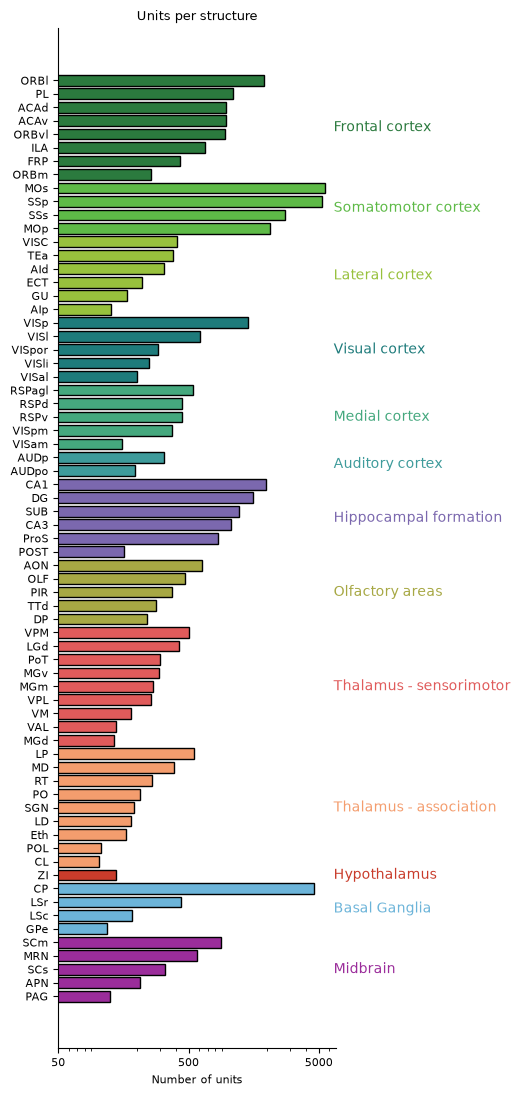

In [20]:
#bar plot of total units recorded per structure

min_n_units=100
min_n_sessions=1

n_sessions_by_structure=sel_units.groupby('structure')['session_id'].nunique()
n_units_by_structure=sel_units['structure'].value_counts()
n_units_sessions_by_structure_table=pd.merge(
    n_units_by_structure,n_sessions_by_structure,left_index=True,right_index=True,how='outer',suffixes=('_n_units','_n_sessions')
    ).query('count>@min_n_units and session_id>=@min_n_sessions').sort_values(by='count', ascending=True)

merged_table = pd.merge(
    n_units_sessions_by_structure_table,
    simplified_structure_by_structure_df,
    on='structure',
    how='left'
).sort_values(by=['structure_group_order','count'],ascending=[False,True]).reset_index()

fig,ax=plt.subplots(1,1,figsize=(3.5,11))
ax.barh(merged_table['structure'], merged_table['count'],
      color=merged_table['structure_color'], edgecolor='k')
ax.set_xlabel('Number of units')
ax.set_title('Units per structure')
ax.set_xscale('log')
ax.set_xticks([50,500,5000])
ax.set_xticklabels(['50','500','5000'])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

# plot text of structure group
for sg, group_df in merged_table.groupby('structure_group'):
    ax.text(6500, group_df.index.values.mean(), sg,
               ha='left', va='center', color=group_df['structure_color'].iloc[0], fontsize=10)


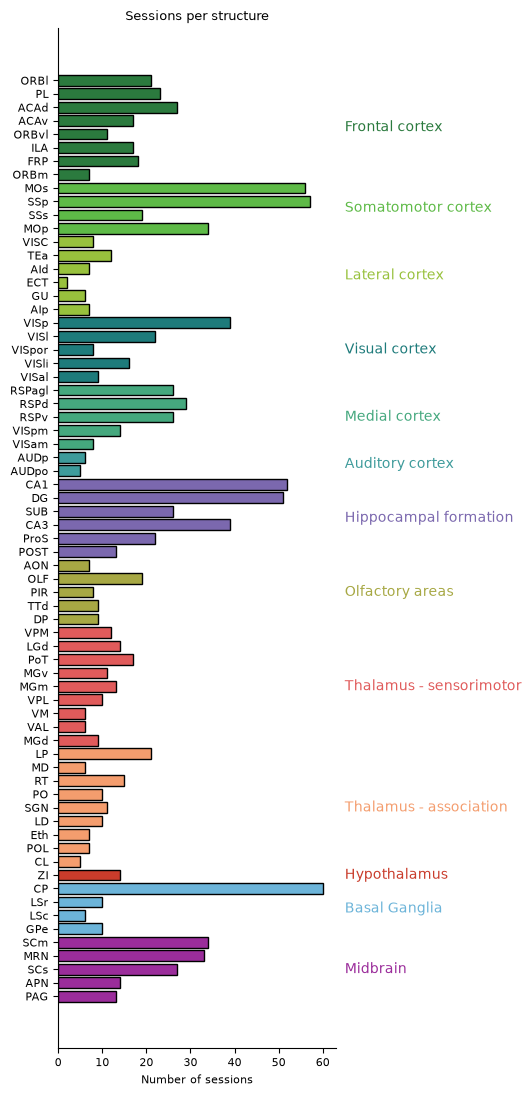

In [21]:
#bar plot of sessions per structure

min_n_units=100
min_n_sessions=1

n_sessions_by_structure=sel_units.groupby('structure')['session_id'].nunique()
n_units_by_structure=sel_units['structure'].value_counts()
n_units_sessions_by_structure_table=pd.merge(
    n_units_by_structure,n_sessions_by_structure,left_index=True,right_index=True,how='outer',suffixes=('_n_units','_n_sessions')
    ).query('count>@min_n_units and session_id>=@min_n_sessions').sort_values(by='count', ascending=True)

merged_table = pd.merge(
    n_units_sessions_by_structure_table,
    simplified_structure_by_structure_df,
    on='structure',
    how='left'
).sort_values(by=['structure_group_order','count'],ascending=[False,True]).reset_index()

fig,ax=plt.subplots(1,1,figsize=(3.5,11))
ax.barh(merged_table['structure'], merged_table['session_id'],
      color=merged_table['structure_color'], edgecolor='k')
ax.set_xlabel('Number of sessions')
ax.set_title('Sessions per structure')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

# plot text of structure group
for sg, group_df in merged_table.groupby('structure_group'):
    ax.text(65, group_df.index.values.mean(), sg,
               ha='left', va='center', color=group_df['structure_color'].iloc[0], fontsize=10)


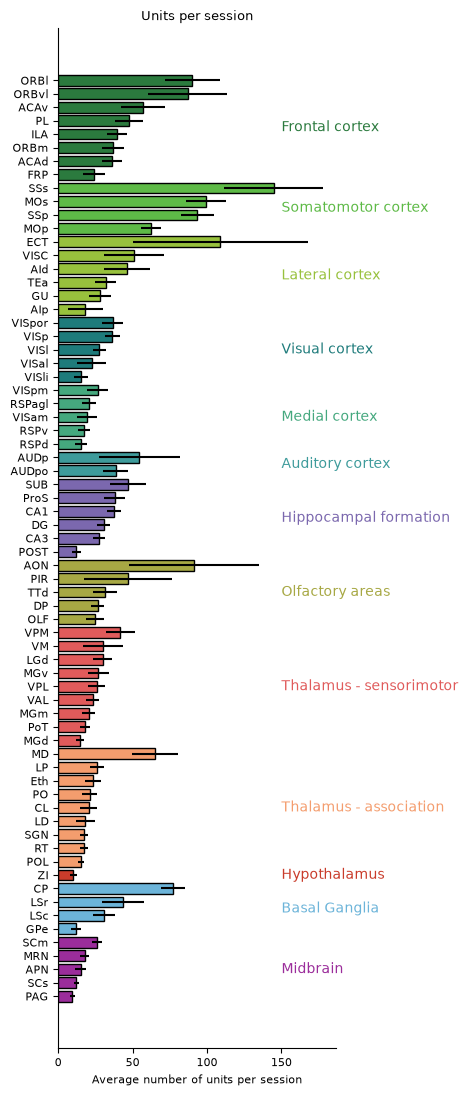

In [22]:
#bar plot of average units recorded per structure per session

min_n_units=100
min_n_sessions=1

n_sessions_by_structure=sel_units.groupby('structure')['session_id'].nunique()
n_units_by_structure=sel_units['structure'].value_counts()

n_units_sessions_by_structure_table=pd.merge(
    n_units_by_structure,n_sessions_by_structure,left_index=True,right_index=True,how='outer',suffixes=('_n_units','_n_sessions')
    ).query('count>@min_n_units and session_id>=@min_n_sessions')

structure_sem ={
    'structure':[],
    'sem':[],
}
n_units_by_session_structure=sel_units.groupby(['structure','session_id'])['unit_id'].nunique()
for structure in sel_units['structure'].unique():
    structure_units = n_units_by_session_structure.loc[structure]
    sem = structure_units.sem()
    structure_sem['structure'].append(structure)
    structure_sem['sem'].append(sem)

structure_sem_df = pd.DataFrame(structure_sem)

n_units_sessions_by_structure_table = pd.merge(
    n_units_sessions_by_structure_table,
    structure_sem_df,
    on='structure',
    how='left'
)

n_units_sessions_by_structure_table['avg_units_per_session'] = n_units_sessions_by_structure_table['count'] / n_units_sessions_by_structure_table['session_id']

n_units_sessions_by_structure_table = n_units_sessions_by_structure_table.sort_values(by='avg_units_per_session', ascending=True)

merged_table = pd.merge(
    n_units_sessions_by_structure_table,
    simplified_structure_by_structure_df,
    on='structure',
    how='left'
).sort_values(by=['structure_group_order','avg_units_per_session'],ascending=[False,True]).reset_index()

fig,ax=plt.subplots(1,1,figsize=(3.5,11))
ax.barh(merged_table['structure'], merged_table['avg_units_per_session'],
      color=merged_table['structure_color'], edgecolor='k')
ax.errorbar(
    merged_table['avg_units_per_session'],
    merged_table['structure'],
    xerr=merged_table['sem'],
    fmt='none',
    ecolor='k',
    capsize=0
)
ax.set_xlabel('Average number of units per session')
ax.set_title('Units per session')
ax.set_xticks([0,50,100,150])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

# plot text of structure group
for sg, group_df in merged_table.groupby('structure_group'):
    ax.text(150, group_df.index.values.mean(), sg,
               ha='left', va='center', color=group_df['structure_color'].iloc[0], fontsize=10)


C:\Users\ethan.mcbride\AppData\Local\Temp\ipykernel_7384\2549444125.py:37: RuntimeWarning: divide by zero encountered in log
  im=ax.imshow(np.log(simultaneous_recordings_matrix), vmin=np.log(1), vmax=np.log(64), cmap='Greys')


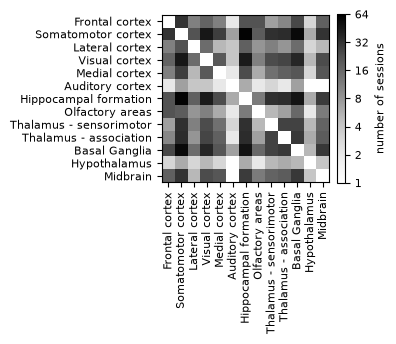

In [26]:
# for each session, get the average predict proba for each structure in the simplified_structure_grouping, and delete the original structure-session row

plot_structures=[
    'Frontal cortex', 'Somatomotor cortex', 'Lateral cortex',
    'Visual cortex', 'Medial cortex', 'Auditory cortex',
    'Hippocampal formation', 'Olfactory areas',
    'Thalamus - sensorimotor', 'Thalamus - association',
    'Basal Ganglia', 'Hypothalamus', 'Midbrain',
]

# get the structures per session with at least 10 units
# use the sel_units table
units_per_structure=sel_units.groupby(['session_id','structure']).size().reset_index(name='unit_count')
units_per_structure=units_per_structure[units_per_structure['unit_count']>=10]

merged_table = units_per_structure.merge(simplified_structure_by_structure_df, on=['structure'], how='inner')

unique_structures=np.array(plot_structures)

simultaneous_recordings_matrix=np.zeros((len(unique_structures), len(unique_structures)))

for session_id in merged_table['session_id'].unique():
    session_structures=merged_table.query('session_id==@session_id and structure_group in @unique_structures')['structure_group'].unique()
    for i in range(len(session_structures)):
        for j in range(i+1, len(session_structures)):
            struct_i=session_structures[i]
            struct_j=session_structures[j]
            idx_i=np.where(np.array(unique_structures)==struct_i)[0][0]
            idx_j=np.where(np.array(unique_structures)==struct_j)[0][0]
            simultaneous_recordings_matrix[idx_i, idx_j] += 1
            simultaneous_recordings_matrix[idx_j, idx_i] += 1


from matplotlib.colors import LogNorm
import matplotlib.ticker as mticker
fig,ax=plt.subplots(1,1,figsize=(4,4))
im=ax.imshow(np.log(simultaneous_recordings_matrix), vmin=np.log(1), vmax=np.log(64), cmap='Greys')
ax.set_xticks(np.arange(len(unique_structures)))
ax.set_yticks(np.arange(len(unique_structures)))
ax.set_xticklabels(unique_structures, rotation=90, ha='center')
ax.set_yticklabels(unique_structures)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='number of sessions',
             ticks=np.log([1, 2, 4, 8, 16, 32, 64]), format=mticker.FixedFormatter([1, 2, 4, 8, 16, 32, 64]))

fig.tight_layout()
